# How can we evaluate players off the ball?

### A beginner-friendly walk through SkillCorner's open football data

An outfield player has the ball for only a minute or two in a typical match. The rest of the time they are moving: making space, dragging defenders around, and offering teammates a pass. Traditional stats like goals, assists and passes mostly ignore that.

This notebook uses free data from **SkillCorner** to measure one big part of off-ball play: **off-ball runs**. It works through five steps:

1. **The source**: what SkillCorner's data is and how we get it
2. **The raw data**: what the file looks like and how it is organised
3. **Cleaning**: turning it into a simple, readable table
4. **Checking**: making sure the numbers add up
5. **A chart and summary**: what it tells us about evaluating players off the ball

**How to use this notebook:** the grey boxes contain code, and the text above each one explains what it does. You don't need to change anything. In VS Code, click **Run All** at the top. The first time, it may ask you to pick a "kernel"; choose the one called **`.venv`**.

---
## Step 1: The source and how we access it

### What is SkillCorner?

SkillCorner is a company that produces **tracking data from ordinary TV broadcasts**. Computer-vision software watches the match video and records the position of every visible player and the ball **10 times per second**. (When a player is off-screen, it estimates where they are.)

From those positions, SkillCorner automatically detects game events, including **off-ball runs**: moments when a player without the ball makes a purposeful movement while a teammate has it. Each run is sorted into one of 10 types (for example a run *in behind* the defence, a run *coming short* towards the ball, or an *overlap* around a teammate). SkillCorner also records what happened next: did a teammate pass to the runner, did the runner get the ball, and was the run *dangerous*?

### What is in the open data?

SkillCorner and PySport publish a free sample on GitHub at **[github.com/SkillCorner/opendata](https://github.com/SkillCorner/opendata)**. It covers the **2024/25 Australian A-League** and contains:

| Folder / file | What it holds |
|---|---|
| `data/matches.json` | A list of 10 sample matches |
| `data/matches/<match id>/` | For each of those 10 matches: full tracking data, every detected event, and "phases of play" |
| `data/aggregates/` | **Season summaries for every player in the league**: physical output, off-ball runs, and passing |

### Which file we use, and why

We use **`aus1league_obraggregates_20242025.csv`** ("OBR" stands for **O**ff-**B**all **R**uns). It summarises every player's off-ball runs **across the whole season**, not just the 10 sample matches. More matches give a fairer picture of a player, because one good or bad game matters less.

### How we access it

No account or password is needed. Every file on GitHub has a "raw" web address, and Python can download it directly, just like clicking a download link.

Two details:
* We point at a **fixed version** of the repository (a specific "commit"). If SkillCorner updates its files later, this notebook still gets exactly the same data and gives the same results.
* We save a copy into this project's `data/raw/` folder, so the file is downloaded only once.

*SkillCorner asks anyone using the data to credit them: the data in this notebook is © SkillCorner, shared through its open-data initiative with PySport.*

**Code: load the toolkits.** Python on its own is fairly bare, so we load some add-on toolkits:
* **pandas** handles tables of data (think of it as Excel inside Python)
* **matplotlib** draws charts
* **pathlib** and **urllib** handle folders and downloads

The settings at the bottom only control how tables are displayed on screen.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# Show tables neatly: all columns visible, numbers to 2 decimal places
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:.2f}".format)

print("Toolkits loaded. pandas version:", pd.__version__)

Toolkits loaded. pandas version: 3.0.6


**Code: download the file.** This box:
1. Builds the web address of the off-ball runs file, using the fixed version of the repository.
2. Works out where to save it (the project's `data/raw/` folder).
3. Downloads it only if we don't already have a copy.
4. Opens it as a table called `raw`.

In [2]:
# The fixed version (commit) of SkillCorner's repository we read from
REPO_VERSION = "4340d274572876239c154c90bc507a9b3250a656"
BASE_URL = f"https://raw.githubusercontent.com/SkillCorner/opendata/{REPO_VERSION}/data"
OBR_URL = f"{BASE_URL}/aggregates/aus1league_obraggregates_20242025.csv"

# Find the project folder, whether this runs from the notebooks/ folder or the project root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = PROJECT_ROOT / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

obr_file = RAW_DIR / "aus1league_obraggregates_20242025.csv"
if not obr_file.exists():
    print("Downloading from:", OBR_URL)
    urlretrieve(OBR_URL, obr_file)
else:
    print("Already downloaded. Using the saved copy.")

raw = pd.read_csv(obr_file)
print(f"Saved at: {obr_file}")
print(f"File size: {obr_file.stat().st_size / 1024:.0f} KB")

Saved at: C:\Users\maxwe\Skill-Corner-Tracking-Data-Dashboard\data\raw\aus1league_obraggregates_20242025.csv
File size: 258 KB


---
## Step 2: The raw data and its structure

Before changing anything, we look at the data exactly as SkillCorner provides it.

**Code: the size and the first few rows.** `shape` gives the number of rows and columns. `head()` shows the first 5 rows.

In [3]:
rows, cols = raw.shape
print(f"The raw file has {rows} rows and {cols} columns.\n")
raw.head()

The raw file has 407 rows and 130 columns.



,competition_edition_id,competition_id,competition_name,season_id,season_name,player_id,player_name,player_short_name,player_birthdate,team_id,team_name,position_group,minutes,minutes_tip,minutes_otip,...,pullingwiderun_count_dangerous_targeted_p30tip,aheadoftheballrun_count_dangerous_targeted_p30tip,supportrun_count_dangerous_targeted_p30tip,underlaprun_count_dangerous_targeted_p30tip,offballrun_count_dangerous_received_p30tip,behindrun_count_dangerous_received_p30tip,comingshortrun_count_dangerous_received_p30tip,crossreceiverrun_count_dangerous_received_p30tip,droppingoffrun_count_dangerous_received_p30tip,overlaprun_count_dangerous_received_p30tip,pullinghalfspacerun_count_dangerous_received_p30tip,pullingwiderun_count_dangerous_received_p30tip,aheadoftheballrun_count_dangerous_received_p30tip,supportrun_count_dangerous_received_p30tip,underlaprun_count_dangerous_received_p30tip
0,870,61,AUS - A-League,95,2024/2025,211,Adam Taggart,A. Taggart,1993-06-02,871,Perth Glory Football Club,Center Forward,97.47,22.83,32.10,...,0.00,2.02,0.61,0.00,4.35,1.62,0.00,1.11,0.00,0.00,0.00,0.00,1.21,0.40,0.00
1,870,61,AUS - A-League,95,2024/2025,218,Adama Traoré,A. Traoré,1990-02-03,868,Melbourne Victory Football Club,Full Back,89.00,26.23,19.77,...,0.00,0.57,0.00,0.00,1.14,0.00,0.00,0.57,0.00,0.00,0.00,0.00,0.57,0.00,0.00
2,870,61,AUS - A-League,95,2024/2025,2759,Dino Arslanagić,D. Arslanagić,1993-04-24,1804,Macarthur FC,Central Defender,96.57,27.05,28.14,...,0.00,0.16,0.00,0.00,0.16,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.16,0.00,0.00
3,870,61,AUS - A-League,95,2024/2025,2858,Douglas Costa de Souza,Douglas Costa,1990-09-14,869,Sydney Football Club,Center Forward,92.87,28.20,24.48,...,0.00,0.35,0.71,0.00,1.42,0.71,0.00,0.00,0.00,0.00,0.00,0.00,0.35,0.35,0.00
4,870,61,AUS - A-League,95,2024/2025,2858,Douglas Costa de Souza,Douglas Costa,1990-09-14,869,Sydney Football Club,Midfield,67.56,20.57,17.91,...,0.00,1.46,1.46,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


That is a wide table: **130 columns**. Scroll sideways in the output above to see more of them. Most of the columns follow a pattern, so they are easier to read once you know it.

**Code: sort the columns into groups.** This box groups the 130 columns by what they describe and prints a few examples from each group.

In [4]:
run_types = ["behindrun", "comingshortrun", "crossreceiverrun", "droppingoffrun", "overlaprun",
             "pullinghalfspacerun", "pullingwiderun", "aheadoftheballrun", "supportrun", "underlaprun"]

about_player = [c for c in raw.columns if not c.startswith(("offballrun", *run_types))]
all_runs     = [c for c in raw.columns if c.startswith("offballrun")]
by_run_type  = [c for c in raw.columns if c.startswith(tuple(run_types))]

print(f"1) Who / when / how much they played: {len(about_player)} columns")
print("   ", about_player, "\n")
print(f"2) All off-ball runs combined: {len(all_runs)} columns")
print("   ", all_runs, "\n")
print(f"3) The same measures split by the 10 run types: {len(by_run_type)} columns")
print("    e.g.", by_run_type[:4], "...")

1) Who / when / how much they played: 18 columns
    ['competition_edition_id', 'competition_id', 'competition_name', 'season_id', 'season_name', 'player_id', 'player_name', 'player_short_name', 'player_birthdate', 'team_id', 'team_name', 'position_group', 'minutes', 'minutes_tip', 'minutes_otip', 'performance_count', 'performance_included_count', 'performance_failed_count'] 

2) All off-ball runs combined: 12 columns
    ['offballrun_count_total', 'offballrun_count_p30tip', 'offballrun_count_shotwithin10s_p30tip', 'offballrun_count_goalwithin10s_p30tip', 'offballrun_count_targeted_p30tip', 'offballrun_count_received_p30tip', 'offballrun_avgdistance', 'offballrun_count_abovehsr_p30tip', 'offballrun_count_penaltyarea_p30tip', 'offballrun_count_dangerous_p30tip', 'offballrun_count_dangerous_targeted_p30tip', 'offballrun_count_dangerous_received_p30tip'] 

3) The same measures split by the 10 run types: 100 columns
    e.g. ['behindrun_count_p30tip', 'comingshortrun_count_p30tip', 'crossr

### How to read the column names

**Group 1** says *who* the row is about: player, team, birthdate, and **position group** (Center Forward, Wide Attacker, Midfield, Full Back, Central Defender, Goalkeeper). It also says how much they played:

| Column | Meaning |
|---|---|
| `performance_included_count` | Number of matches counted for this player |
| `minutes` | Average minutes played **per match** |
| `minutes_tip` | Average minutes per match that the player's **team had the ball** ("TIP" = Team In Possession) |
| `minutes_otip` | Average minutes per match that the **opponent had the ball** ("OTIP") |

**Groups 2 and 3** are built like a sentence: **`[run type]_count_[outcome]_p30tip`**

* **Run type**: `offballrun` means all runs combined; otherwise one of the 10 types, e.g. `behindrun` (in behind the defence), `comingshortrun` (towards the ball), `overlaprun` (around the outside of a teammate)
* **Outcome** (optional): which runs to count
  * *(none)*: every run
  * `targeted`: the teammate on the ball **passed to the runner**
  * `received`: the runner **actually got the ball**
  * `dangerous`: SkillCorner judged the run **valuable**: if the runner got the ball there, the team's chance of scoring would rise noticeably
  * `shotwithin10s` / `goalwithin10s`: the team shot / scored within 10 seconds
  * `abovehsr`: run at **high speed** (above the high-speed-running threshold)
  * `penaltyarea`: run into the penalty area
* **`p30tip`** = **per 30 minutes of the team having the ball**

### Why "per 30 minutes of possession"?

You can only make an off-ball run *for your team* when your team has the ball. A striker in a team that dominates possession gets far more chances to run than a striker in a team that defends all game. Dividing by possession time puts them on a level playing field. Thirty minutes is roughly how long a team has the ball in a typical match, so the numbers read roughly as "runs per game".

**Code: look at one player.** Here is one full row, for Perth Glory striker Adam Taggart, showing only the "all runs combined" columns so it fits on screen.

In [5]:
one_player = raw[(raw["player_name"] == "Adam Taggart") & (raw["position_group"] == "Center Forward")]
one_player[["player_name", "team_name", "position_group", "performance_included_count",
            "minutes", "minutes_tip"] + all_runs].T.rename(columns=lambda _: "value")

,value
player_name,Adam Taggart
team_name,Perth Glory Football Club
position_group,Center Forward
performance_included_count,13
minutes,97.47
minutes_tip,22.83
offballrun_count_total,354.00
offballrun_count_p30tip,35.78
offballrun_count_shotwithin10s_p30tip,2.83
offballrun_count_goalwithin10s_p30tip,0.30


**Reading Taggart's row:** across 13 matches, his team had the ball for about 23 minutes per game while he was on the pitch. In that time he made **354 off-ball runs**, which works out to about **36 runs per 30 minutes of possession**. About 25 of those 36 were rated *dangerous*. A teammate passed to him (`targeted`) on about 15 of them, and he actually received the ball on about 7.

### Where do these numbers come from?

The season file is a **summary**. To see what a single "run" is, we can open one of the 10 match files, which list every individual event.

**Code: one match's event list.** This downloads the event file for one match (about 5 MB) and shows a few of its off-ball runs.

In [6]:
MATCH_ID = 1925299
events_file = RAW_DIR / f"{MATCH_ID}_dynamic_events.csv"
if not events_file.exists():
    urlretrieve(f"{BASE_URL}/matches/{MATCH_ID}/{MATCH_ID}_dynamic_events.csv", events_file)

events = pd.read_csv(events_file, low_memory=False)
print(f"This match has {len(events):,} events. They come in four kinds:")
print(events["event_type"].value_counts().to_string(), "\n")

runs = events[events["event_type"] == "off_ball_run"]
runs[["player_name", "team_shortname", "event_subtype", "minute_start", "duration",
      "distance_covered", "speed_avg", "targeted", "received", "dangerous"]].head(8)

This match has 5,222 events. They come in four kinds:
event_type
passing_option        2734
player_possession     1054
on_ball_engagement     936
off_ball_run           498 



,player_name,team_shortname,event_subtype,minute_start,duration,distance_covered,speed_avg,targeted,received,dangerous
1,T. Waddingham,Brisbane FC,run_ahead_of_the_ball,0,2.40,13.80,20.61,True,False,False
10,B. Warland,Brisbane FC,dropping_off,0,2.90,12.88,16.44,True,True,False
11,H. Van Der Saag,Brisbane FC,pulling_wide,0,1.50,6.35,16.16,False,False,False
15,A. Burke-Gilroy,Brisbane FC,dropping_off,0,2.10,10.01,17.73,True,True,False
19,J. O'Shea,Brisbane FC,coming_short,0,1.80,7.66,15.30,False,False,False
25,A. Burke-Gilroy,Brisbane FC,support,0,1.50,8.11,21.08,False,False,False
30,K. Jelacic,Brisbane FC,coming_short,0,1.10,4.53,16.11,False,False,False
31,A. Burke-Gilroy,Brisbane FC,run_ahead_of_the_ball,0,1.50,9.69,24.40,True,False,False


Each row above is **one run by one player**: the type of run, when it happened, how long it lasted (seconds), how far the player went (metres), their average speed (km/h), and the yes/no outcomes (`targeted`, `received`, `dangerous`). SkillCorner adds up these rows across every match of the season, per player, to build the season file. That season file is what we use from here on.

---
## Step 3: Clean it into a simple table

The raw file is accurate but hard to read. Cleaning means **deciding what to keep, removing what can't be trusted, and naming things clearly**. Here are the decisions, with reasons:

1. **Remove empty rows.** Two players have no numbers at all, because SkillCorner couldn't process their only match.
2. **Remove goalkeepers.** They don't make attacking runs, so they would only clutter comparisons.
3. **Keep only players with at least 5 matches in a position.** With one or two matches, a player can look brilliant or terrible by chance. Five is a common minimum; it isn't a magic number.
4. **Keep about a dozen useful columns** out of 130, and give them plain-English names.
5. **Add percentages**, such as "what share of a player's runs were dangerous", which are easier to compare than raw counts.

**One important quirk:** a row is **one player *in one position***, not just one player. If someone played as both a winger and a striker, they get two rows, because the runs we expect from a winger and a striker are different. After the minimum-match filter, about a dozen players appear twice.

**Code: build the clean table.**

In [7]:
MIN_MATCHES = 5

clean = raw.copy()
clean = clean.dropna(subset=["minutes"])                         # 1. drop empty rows
clean = clean[clean["position_group"] != "Goalkeeper"]           # 2. drop goalkeepers
clean = clean[clean["performance_included_count"] >= MIN_MATCHES]  # 3. enough matches

# 4. pick useful columns and give them plain-English names
clean = clean.rename(columns={
    "player_short_name": "player",
    "team_name": "team",
    "position_group": "position",
    "performance_included_count": "matches",
    "offballrun_count_total": "total_runs",
    "offballrun_count_p30tip": "runs_per30",
    "offballrun_count_dangerous_p30tip": "dangerous_runs_per30",
    "offballrun_count_targeted_p30tip": "targeted_runs_per30",
    "offballrun_count_received_p30tip": "received_runs_per30",
    "behindrun_count_p30tip": "runs_in_behind_per30",
    "offballrun_count_abovehsr_p30tip": "high_speed_runs_per30",
    "offballrun_avgdistance": "avg_run_length_m",
})

# 5. add percentages (all per-30 numbers share the same base, so dividing them is fair)
clean["pct_dangerous"] = 100 * clean["dangerous_runs_per30"] / clean["runs_per30"]
clean["pct_passed_to"] = 100 * clean["targeted_runs_per30"] / clean["runs_per30"]
clean["pct_received"]  = 100 * clean["received_runs_per30"] / clean["runs_per30"]

keep = ["player", "team", "position", "matches", "total_runs", "runs_per30",
        "dangerous_runs_per30", "pct_dangerous", "pct_passed_to", "pct_received",
        "runs_in_behind_per30", "high_speed_runs_per30", "avg_run_length_m"]
clean = clean[keep].sort_values("dangerous_runs_per30", ascending=False).reset_index(drop=True)
clean["total_runs"] = clean["total_runs"].astype(int)

print(f"Raw file: {len(raw)} rows x {raw.shape[1]} columns")
print(f"Clean table: {len(clean)} rows x {clean.shape[1]} columns "
      f"({clean['player'].nunique()} different players)")
clean.head(10)

Raw file: 407 rows x 130 columns
Clean table: 173 rows x 13 columns (161 different players)


,player,team,position,matches,total_runs,runs_per30,dangerous_runs_per30,pct_dangerous,pct_passed_to,pct_received,runs_in_behind_per30,high_speed_runs_per30,avg_run_length_m
0,A. Goodwin,Adelaide United Football Club,Center Forward,14,418,40.30,31.33,77.74,33.72,11.96,10.61,14.65,14.47
1,L. Rose,Newcastle United Jets FC,Center Forward,5,192,44.19,28.77,65.11,30.73,13.53,14.27,14.04,14.01
2,N. Vergos,Melbourne Victory Football Club,Center Forward,15,405,37.17,27.26,73.34,30.37,14.31,9.18,11.01,13.98
3,M. Caputo,Melbourne City FC,Center Forward,12,344,34.96,26.01,74.40,35.18,16.56,9.55,7.72,12.88
4,B. Gibson,Newcastle United Jets FC,Center Forward,7,229,36.48,25.65,70.31,32.76,16.58,8.60,12.75,14.83
5,N. Botić,Western United,Center Forward,18,577,40.43,25.64,63.42,27.03,14.91,9.25,12.12,14.10
6,A. Taggart,Perth Glory Football Club,Center Forward,13,354,35.78,25.27,70.63,43.21,20.07,9.60,11.62,13.72
7,A. Segecic,Sydney Football Club,Wide Attacker,6,241,48.30,25.05,51.86,31.53,20.33,10.22,13.63,14.26
8,G. May,Auckland FC,Center Forward,15,577,49.90,24.47,49.04,37.62,24.09,5.10,13.40,13.53
9,T. Waddingham,Brisbane Roar FC,Center Forward,7,165,34.54,23.86,69.08,31.53,14.53,8.58,8.16,13.40


The table above is sorted by **dangerous runs per 30 minutes of possession**, and every column now has a readable name:

| Column | Meaning |
|---|---|
| `matches` | Matches counted in this position |
| `total_runs` | All off-ball runs across those matches |
| `runs_per30` | Runs per 30 min of team possession: **how often they move** |
| `dangerous_runs_per30` | Dangerous runs per 30 min of possession: **how often they move somewhere valuable** |
| `pct_dangerous` | Share of their runs that were dangerous: **quality of movement** |
| `pct_passed_to` / `pct_received` | Share of runs where a teammate passed to them / they got the ball |
| `runs_in_behind_per30` | Runs in behind the defence per 30 min |
| `high_speed_runs_per30` | Runs above high-speed-running pace per 30 min |
| `avg_run_length_m` | Average run length in metres |

**Code: save the clean table** as a CSV file (opens in Excel) in `data/processed/`, so it can be reused without repeating these steps.

In [8]:
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
clean_file = PROCESSED_DIR / "off_ball_runs_clean.csv"
clean.to_csv(clean_file, index=False)
print("Saved clean table to:", clean_file)

Saved clean table to: C:\Users\maxwe\Skill-Corner-Tracking-Data-Dashboard\data\processed\off_ball_runs_clean.csv


---
## Step 4: Check that the numbers look right

Before drawing conclusions, we test the data. Each check below is a statement that **must** be true if the data is sound. The code prints ✅ if it holds and ❌ if it doesn't.

* **Nothing missing or duplicated**: every row is complete, and no player-position pair appears twice.
* **Sensible ranges**: no negative counts, and every percentage between 0 and 100.
* **The rate matches the raw count.** We recalculate "runs per 30 minutes" ourselves from the total runs, matches and possession minutes, then compare it with SkillCorner's figure.
* **The parts add up to the whole.** The 10 run types should sum to the total.
* **The funnel narrows.** You can't receive a pass you weren't passed, so *received ≤ passed to ≤ all runs*. Likewise *dangerous ≤ all runs*.

Small differences of a few hundredths are expected, because SkillCorner rounds its figures to 2 decimal places.

**Code: run the checks.** We check against the raw file, restricted to the same rows we kept.

In [9]:
def check(description, passed, detail=""):
    print(("✅ " if passed else "❌ ") + description + (f"  ({detail})" if detail else ""))

# The raw rows that made it into the clean table
kept = raw.dropna(subset=["minutes"])
kept = kept[(kept["position_group"] != "Goalkeeper") & (kept["performance_included_count"] >= MIN_MATCHES)]

# Nothing missing or duplicated
check("No missing values in the clean table", clean.isna().sum().sum() == 0)
check("No player-position pair appears twice",
      not kept.duplicated(subset=["player_id", "team_id", "position_group"]).any())

# Sensible ranges
numbers = clean.select_dtypes("number")
check("No negative numbers", (numbers >= 0).all().all())
pct_cols = ["pct_dangerous", "pct_passed_to", "pct_received"]
check("All percentages are between 0 and 100", clean[pct_cols].apply(lambda s: s.between(0, 100)).all().all())

# Rate matches raw count:  total runs / (possession minutes per match x matches) x 30
recalculated = kept["offballrun_count_total"] / (kept["minutes_tip"] * kept["performance_included_count"]) * 30
gap = (recalculated - kept["offballrun_count_p30tip"]).abs().max()
check("Our own 'runs per 30' calculation matches SkillCorner's", gap < 0.05, f"largest gap {gap:.3f}")

# Parts add up to the whole
type_sum = kept[[f"{t}_count_p30tip" for t in run_types]].sum(axis=1)
gap = (type_sum - kept["offballrun_count_p30tip"]).abs().max()
check("The 10 run types add up to the total", gap < 0.05, f"largest gap {gap:.3f}")

# The funnel narrows
tiny = 1e-9
check("Passed to <= all runs", (kept["offballrun_count_targeted_p30tip"] <= kept["offballrun_count_p30tip"] + tiny).all())
check("Received <= passed to", (kept["offballrun_count_received_p30tip"] <= kept["offballrun_count_targeted_p30tip"] + tiny).all())
check("Dangerous <= all runs", (kept["offballrun_count_dangerous_p30tip"] <= kept["offballrun_count_p30tip"] + tiny).all())

✅ No missing values in the clean table
✅ No player-position pair appears twice
✅ No negative numbers
✅ All percentages are between 0 and 100
✅ Our own 'runs per 30' calculation matches SkillCorner's  (largest gap 0.013)
✅ The 10 run types add up to the total  (largest gap 0.020)
✅ Passed to <= all runs
✅ Received <= passed to
✅ Dangerous <= all runs


**Code: does it make football sense?** Passing the logic checks doesn't guarantee the numbers mean what we think. As a final test, we compare the **typical (median) player in each position**. If the data is right, we'd expect:
* **centre-backs** to make the fewest runs (they stay back)
* **forwards and wingers** to make the most runs, and the most dangerous ones
* **strikers** to have the highest share of runs in behind the defence

In [10]:
by_position = (clean.groupby("position")
               [["runs_per30", "dangerous_runs_per30", "pct_dangerous", "runs_in_behind_per30", "avg_run_length_m"]]
               .median()
               .sort_values("dangerous_runs_per30", ascending=False))
by_position.insert(0, "players", clean["position"].value_counts())
by_position

,players,runs_per30,dangerous_runs_per30,pct_dangerous,runs_in_behind_per30,avg_run_length_m
position,,,,,,
Center Forward,26,36.13,22.86,64.26,7.34,13.98
Wide Attacker,31,38.51,13.79,34.39,3.18,14.33
Full Back,37,25.36,3.97,17.16,0.65,14.15
Midfield,41,27.70,3.33,14.36,0.24,12.02
Central Defender,38,8.87,0.22,2.88,0.00,10.95


It matches football intuition. The typical **centre-back** makes about 9 runs per 30 minutes of possession, and only 3% of them are dangerous. **Strikers** (Center Forward) make the most dangerous runs, around 23 per 30 minutes, with about two-thirds of their runs rated dangerous. **Wingers** make the most runs overall. **Full-backs** and **midfielders** sit in between.

This also gives our most important lesson for evaluating players: **compare players only with others in the same position.** A centre-back with "few dangerous runs" isn't a bad player; it's simply not their job.

**One small quirk we found.** Goals should never outnumber shots, since you can't score without shooting. In the raw file, one player (N. Pijnaker) has slightly more "runs followed by a goal" than "runs followed by a shot" (0.1 vs 0.0 per 30 minutes). It's tiny, and possibly an edge case such as an own goal being counted as a goal but not as a shot. We don't use the goal or shot columns in our table, so it doesn't affect anything here, but it's worth knowing that no dataset is perfect.

In [11]:
quirk = raw[raw["offballrun_count_goalwithin10s_p30tip"] > raw["offballrun_count_shotwithin10s_p30tip"]]
quirk[["player_short_name", "position_group", "offballrun_count_shotwithin10s_p30tip",
       "offballrun_count_goalwithin10s_p30tip"]]

,player_short_name,position_group,offballrun_count_shotwithin10s_p30tip,offballrun_count_goalwithin10s_p30tip
91,N. Pijnaker,Central Defender,0.00,0.10


---
## Step 5: One chart — how often vs. how well attackers move

Since we should compare like with like, the chart focuses on the attackers, **strikers and wingers**, where off-ball runs matter most.

Each dot is one player:
* **Left to right** shows *how often* they make runs (runs per 30 minutes of possession).
* **Bottom to top** shows *how well*: the share of their runs that were dangerous.
* The grey lines mark the **typical (median)** attacker on each measure, which splits the chart into four zones. The **top-right** zone holds players who move often *and* to valuable places.
* A few players are named: the clearest standouts in the top-right zone, plus two strikers in the top-left who make few runs but almost all of them dangerous.

**Code: draw the chart.**

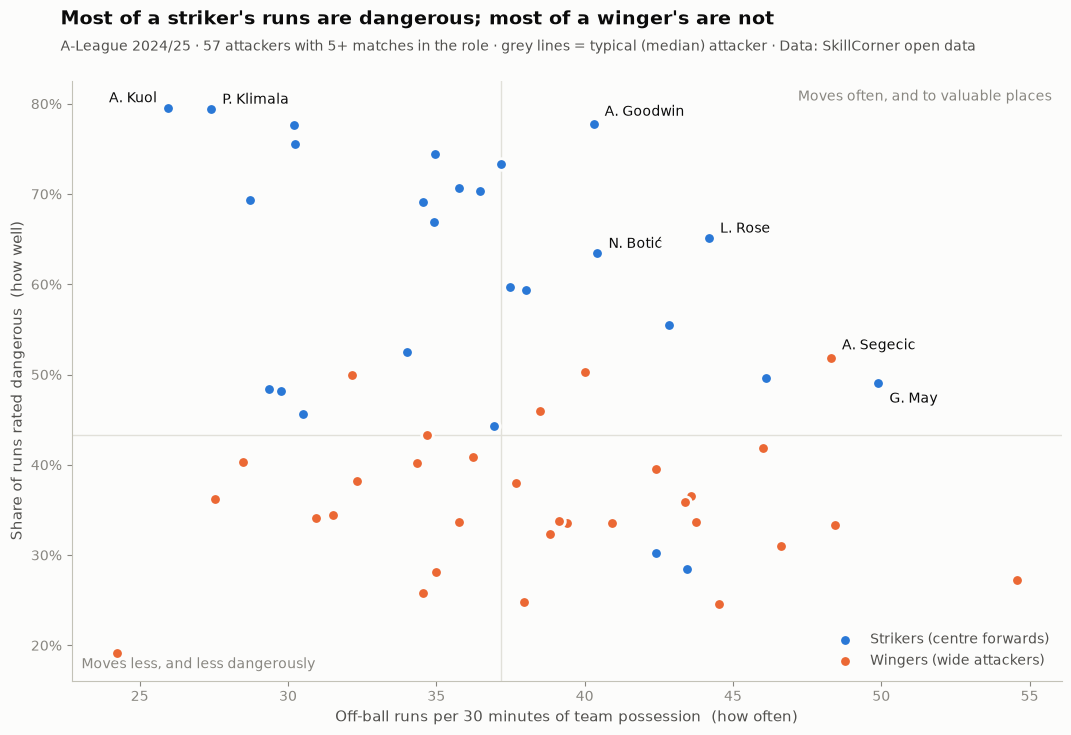

In [12]:
# Colours (chosen to be readable for colour-blind viewers) and quiet greys for the frame
COLOURS = {"Center Forward": "#2a78d6", "Wide Attacker": "#eb6834"}
LABELS  = {"Center Forward": "Strikers (centre forwards)", "Wide Attacker": "Wingers (wide attackers)"}
SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"

attackers = clean[clean["position"].isin(COLOURS)].copy()
mid_x = attackers["runs_per30"].median()
mid_y = attackers["pct_dangerous"].median()

fig, ax = plt.subplots(figsize=(11, 7.5), facecolor=SURFACE)
ax.set_facecolor(SURFACE)

# Median lines and zone labels
ax.axvline(mid_x, color=GRID, lw=1, zorder=1)
ax.axhline(mid_y, color=GRID, lw=1, zorder=1)
ax.text(0.99, 0.985, "Moves often, and to valuable places", transform=ax.transAxes,
        ha="right", va="top", fontsize=10, color=MUTED)
ax.text(0.01, 0.015, "Moves less, and less dangerously", transform=ax.transAxes,
        ha="left", va="bottom", fontsize=10, color=MUTED)

# One set of dots per position (white ring keeps overlapping dots readable)
for position, colour in COLOURS.items():
    group = attackers[attackers["position"] == position]
    ax.scatter(group["runs_per30"], group["pct_dangerous"], s=70, color=colour,
               edgecolor=SURFACE, linewidth=2, label=LABELS[position], zorder=3)

# Name a few players. The numbers nudge each name away from its dot so names don't overlap.
NAMED = {"A. Goodwin": (8, 6), "L. Rose": (8, 4), "N. Botić": (8, 4), "A. Segecic": (8, 6),
         "G. May": (8, -14), "A. Kuol": (-8, 4), "P. Klimala": (8, 4)}
for _, p in attackers[attackers["player"].isin(NAMED)].iterrows():
    dx, dy = NAMED[p["player"]]
    ax.annotate(p["player"], (p["runs_per30"], p["pct_dangerous"]), xytext=(dx, dy),
                textcoords="offset points", fontsize=10, color=INK,
                ha="left" if dx > 0 else "right")

# Axes, title, legend
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel("Off-ball runs per 30 minutes of team possession  (how often)", color=INK_2, fontsize=11)
ax.set_ylabel("Share of runs rated dangerous  (how well)", color=INK_2, fontsize=11)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_color("#c3c2b7")
ax.tick_params(colors=MUTED, labelsize=10)
ax.legend(loc="lower right", frameon=False, fontsize=10, labelcolor=INK_2)

fig.text(0.07, 0.965, "Most of a striker's runs are dangerous; most of a winger's are not",
         fontsize=14, fontweight="bold", color=INK, ha="left")
fig.text(0.07, 0.93, f"A-League 2024/25 · {len(attackers)} attackers with {MIN_MATCHES}+ matches in the role · "
         "grey lines = typical (median) attacker · Data: SkillCorner open data",
         fontsize=10, color=INK_2, ha="left")
fig.subplots_adjust(top=0.89, left=0.08, right=0.98, bottom=0.09)

chart_file = PROJECT_ROOT / "data" / "processed" / "off_ball_runs_chart.png"
fig.savefig(chart_file, dpi=150, facecolor=SURFACE)
plt.show()

### Reading the chart

* **Two clouds.** Strikers (blue) mostly sit high: for a typical striker, about two-thirds of their runs are dangerous, because they run close to goal. Wingers (orange) sit lower, at about one-third, even though they make a similar number of runs or slightly more. This shows again why players should be compared within their own position.
* **Volume and quality are different skills.** Strikers like **A. Kuol** and **P. Klimala** (top-left) make relatively few runs, but nearly 80% of them are dangerous. Others, lower down on the right, run constantly but rarely threaten. A single number would hide that difference, which is why we plot two.
* **Standouts.** In the top-right zone, Adelaide United striker **A. Goodwin** combines high volume with a very high dangerous share (about 78%). **L. Rose**, **N. Botić** and **G. May** are close behind, and winger **A. Segecic** has the best dangerous share of any winger. That's the off-ball profile a recruiter would want to watch on video next. (Rose and Segecic have only 5–6 matches, so treat their numbers with more caution.)

**A caveat:** a dangerous run counts even if the teammate on the ball never passes. This makes sense, because good movement creates value by pulling defenders around even when the ball goes elsewhere. But it also means these numbers show **the quality of a player's movement, not the end result**. To include the end result, look at the `pct_passed_to` and `pct_received` columns in the clean table.

---
## Summary of the full process

**The question:** how can we evaluate what players do *without* the ball?

**1. Source.** SkillCorner turns TV broadcast video into tracking data: every player's position 10 times a second. From that, it automatically detects **off-ball runs**, classifies them into 10 types, and records whether each run was passed to, received, and dangerous. Its free open-data repository on GitHub includes a season summary for every A-League 2024/25 player. We downloaded it directly from a fixed version of the repository, with no account needed, so the results can be reproduced.

**2. Raw data.** A 407-row × 130-column table. Each row is one player in one position. The column names follow the pattern *run type + outcome + "per 30 minutes of team possession"*. That last part adjusts for how much the player's team had the ball, so players from possession-heavy and counter-attacking teams can be compared fairly. To see what a single "run" is, we also looked at one match's event-by-event file.

**3. Cleaning.** We removed 2 empty rows and the goalkeepers, kept only player-positions with at least 5 matches, cut 130 columns down to 13 plain-English ones, and added percentages (share of runs dangerous / passed to / received). The result is saved at `data/processed/off_ball_runs_clean.csv`.

**4. Checks.** All logic checks passed:
* our own recalculated rates match SkillCorner's
* the 10 run types add up to the total
* the funnel always narrows (received ≤ passed to ≤ all runs)
* positions behave as football intuition expects

We found one tiny quirk in a column we don't use.

**5. Findings.** Off-ball value has (at least) two parts: **how often** a player moves, and **how dangerous** those movements are. Both depend heavily on position, so players must be compared with others in the same role. Among attackers, strikers make the most dangerous runs, wingers make the most runs overall, and a handful of players, led by A. Goodwin, stand out on both.

**Ideas for next steps:**
* compare players on specific run types (e.g. runs in behind for strikers, overlaps for full-backs)
* combine this with SkillCorner's **physical** and **passing** season files, which sit in the same folder
* use the 10 match files to put individual runs on a pitch map and watch the clips of the standout players